## 1.1 Testing transforms and plotting 

In [2]:
import sys
sys.path.append('..')

import matplotlib.pyplot as plt
from scipy import signal

import pywt
import numpy as np
import random

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form
from wavelet_transform.test import plotting as test_plot

In [ ]:
def full_plot(nodes, data, t_plot, sampling_rate, title="", frequencies=None):
    """
    Formatted charts for plotting the results from a dwt or dpwt. Combines
    relevant plots including those for the sound wave, frequency content of
    the sound wave (using synthetic data package), and plots of the data at
    each node.

    Parameters
    ----------
    nodes: list
        list of node objects
    data: array_like
        an array of the data from the sound wave
    t_plot: array_like
        the time array to plot the data against
    nyquist_frequency: float
        1/2*sampling rate
    frequencies: list
        list of floats containing the frequencies of the synthetic sound wave
        for the historgram
    """
    # plot data
    fig_1, ax_1 = plt.subplots()
    plot.plot_wave(data, t_plot, ax_1, title)

    # plot transform coefficients all at once
    if frequencies:  # plot a histogram of frequency content in data as well
        fig_2, ax_2 = plt.subplots(2)
        plot.plot_all_final_nodes(nodes, ax_2[0], title)
        plot.plot_frequencies(frequencies, ax_2[1], title)
    else:
        fig_2, ax_2 = plt.subplots()
        plot.plot_all_final_nodes(nodes, ax_2, title)

    # plot each node separately.
    rows = round(len(nodes) / 2)
    fig_3, ax_3 = plt.subplots(rows, 2)
    fig_3.set_size_inches(12, 3 * rows)
    plot.plot_nodes(nodes, ax_3, sampling_rate, rows, columns=2)

    fig_1.tight_layout()
    fig_2.tight_layout()
    fig_3.tight_layout()
    plt.show()

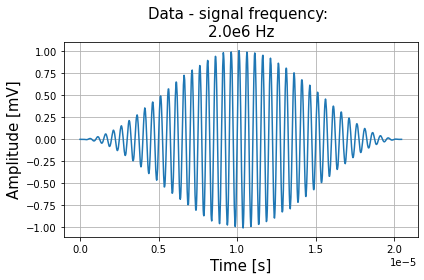

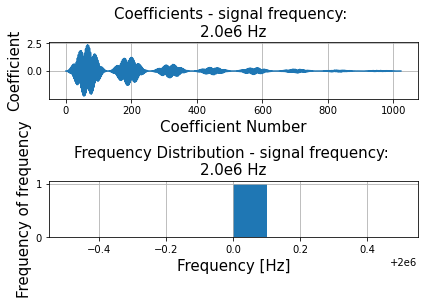

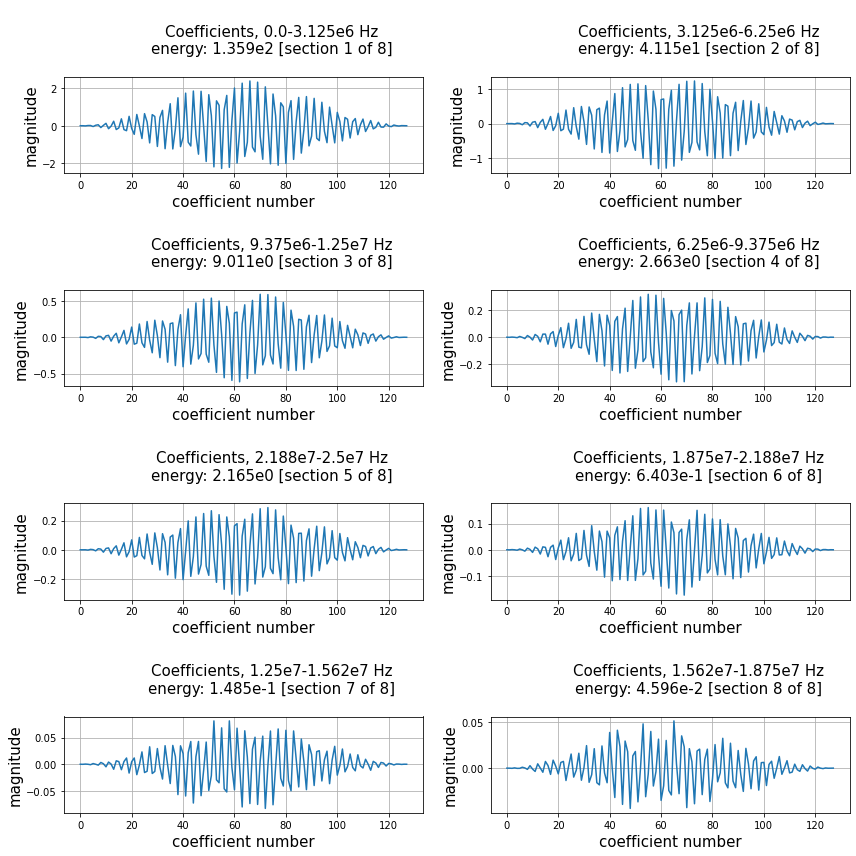

In [3]:
amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6
phase = 0

frequency = 2e6

frequencies = [frequency] # create list of frequencies for synthetic data
time_period = 1/frequency
signal_duration = 100*time_period # duration of the signal is 10 times the test frequency
delay = 0#2*time_period # signal starts 2 time periods late
end = signal_duration#8*time_period # signal ends 2 time periods early

gaussian_noise_std = 0.01 # set the standard devaition of the noise

# generate data
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, 
    sampling_rate, delay, end
    )

# add noise
gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
data += gaussian_noise
data = data[:2**10]
t_plot = t_plot[:2**10]
data = signal.windows.hann(len(data))*data

# transform parameters
levels = 3
db_order = 1
wavelet = f'db{db_order}'
mode = "zero"

# transform
transform_object = wpt.dwpt(data,levels, wavelet, mode)
final_level_nodes = transform_object.get_level(levels)
dwt_nodes = transform_object.dwt_results() # the dwt results can be extracted from the dwpt

# calculate energy
transform_object.calc_frequencies(sampling_rate)

# set title
f = sci_form(frequency)
title = f"- signal frequency: \n{f} Hz"

# plot everything
full_plot(
    final_level_nodes, data, t_plot, sampling_rate, 
    title, frequencies
    )

### Total Energy
Calculating total energy at different levels

In [4]:
from wavelet_transform.utils.statistical_features import energy
t = np.linspace(0, 10, 1000)
data = np.sin(2 * np.pi * t)
data += np.random.normal(0, 1, len(t))
levels = 5
wavelet = "haar"
mode = "zero"
transform_object = wpt.dwpt(data, levels, wavelet, mode)

info = transform_object.info(level=levels, order="freq")
# total_energy = sum(info["energy"])
total_energy = sum(node.energy for node in transform_object.get_level())
total_energy_data = energy(data)
print("sum of node energy:", total_energy)
print("signal energy:", total_energy_data)
print("energy of each node:")
display(info["energy"])

total_energy_dwt = sum(node.energy for node in transform_object.dwt_results())
print("total dwt energy:", total_energy_dwt)

sum of node energy: 1464.213370071934
signal energy: 1464.21337007193
energy of each node:


0     385.884474
1     122.388909
2      22.778740
3      52.396874
4      26.949290
5      32.817250
6      26.498761
7      32.391177
8      34.227740
9      35.228587
10     18.705319
11     42.660143
12     30.753469
13     30.363339
14     24.798106
15     28.208511
16     34.931854
17     36.096161
18     20.895863
19     22.136616
20     29.171862
21     35.073317
22     26.984923
23     34.729852
24     17.950116
25     30.671112
26     47.275975
27     52.905086
28     46.236133
29     23.861352
30     21.831777
31     36.410680
Name: energy, dtype: float64

total dwt energy: 1464.2133700719332


## 1.2 Testing with pywt library

pywt result


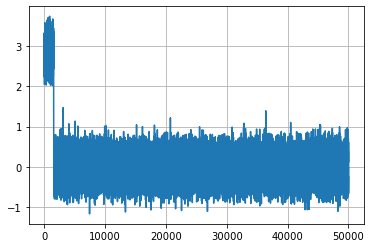

library result


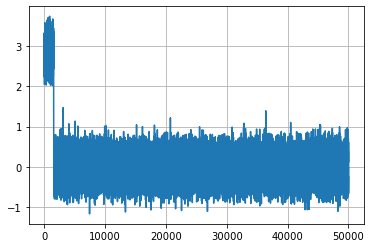

total error 0.0


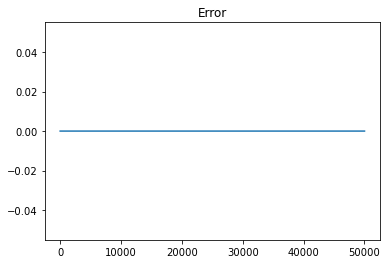

In [5]:
# Test result against pywt library

# Generate data
data = [random.random() for _ in range(50000)]

# Transform settings
levels = 5
wavelet = "haar"
mode = "zero"
pywp_object = pywt.WaveletPacket(data, wavelet, maxlevel=levels, mode=mode)

# pywt result
print("pywt result")
pywt_result = test_plot.plot_pywp_test(pywp_object, levels)

# Library result
print("library result")
obj = wpt.dwpt(data, levels, wavelet, mode)
library_result = test_plot.plot_test(obj.get_level(levels))

# Error calculation
error = pywt_result - library_result
print("total error", np.sum(error))
plt.plot(error)
plt.title("Error")
plt.show()

## 1.3 specifying nodes to plot

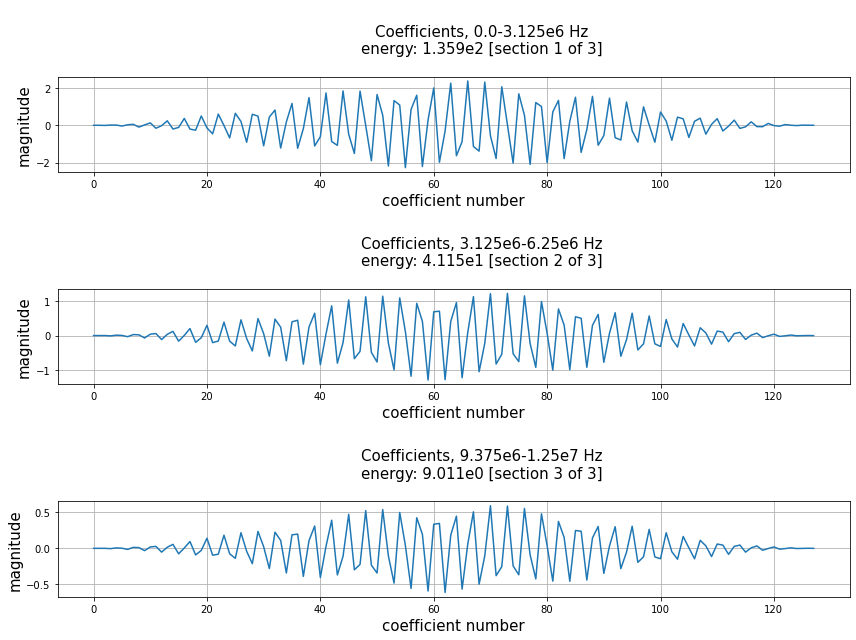

In [6]:
# find nodes with frequencies of interest
frequencies_of_interest = [1e6,1e7,0.5e7]

nodes_of_interest = transform_object.find_nodes(
    final_level_nodes,
    frequencies=frequencies_of_interest
)

# plot data from selected nodes
rows = int(len(nodes_of_interest))

fig,ax = plt.subplots(rows)
plot.plot_nodes(nodes_of_interest,ax,sampling_rate,rows,columns = 1)
fig.set_size_inches(12,3*rows)
fig.tight_layout()

## 2.1 Testing inverse transform

In [7]:
sys.path.append('..')

from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.wpt import transform as wpt
import numpy as np
from wavelet_transform.test import synthetic_data as sd

from scipy.signal import blackmanharris
import matplotlib.pyplot as plt

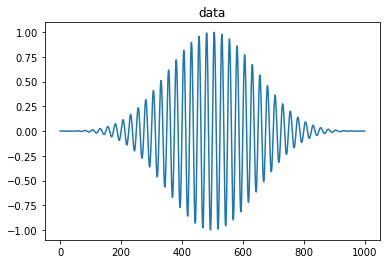

total error dwt: 1.091132524503793e-14
total error, packet 1.6762043613944193e-14


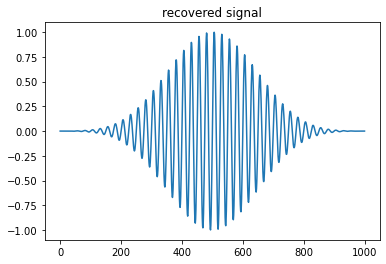

In [8]:
# transform
levels = 8
wavelet = 'db38'
sf = 50e6
freq = 2e6
amp_sin_waves = 1
phase = 0
signal_duration = 1000/sf
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequency, phase, signal_duration, 
    sampling_rate=sf
    )
data = data * blackmanharris(len(data))
plt.plot(data)
plt.title("data")
plt.show()

# Wavelet transform of the data
transform_object = wpt.dwpt(data, levels, wavelet)
transform_object.calc_frequencies(sampling_rate)

# inverse dwt
dwt_inverse = inv.inv_dwt(transform_object)
print('total error dwt:', sum(data - dwt_inverse))

# inverse dwpt
dwpt_inverse = inv.inv_dwpt(transform_object)
print('total error, packet', sum(np.array(data) - dwpt_inverse))
plt.plot(dwpt_inverse)
plt.title("recovered signal")
plt.show()

In [9]:
# testing the reconstruction of separate nodes
rec_1 = inv.inv_dwpt(transform_object, nodes=50)
rec_0 = inv.inv_dwpt(transform_object, nodes=0)
rec_1_0 = inv.inv_dwpt(transform_object, nodes=[0, 50])
error = rec_1_0 - rec_1 - rec_0
print("average error", np.mean(error))

average error 2.3971173548604016e-22


### Info Attributes
Info attributes display statistical measures at each node. InverseTransform.info() calculates these on the recovered signal at each node, while the Transform.info() function calculates these on the wavelet coefficinets at each node.

In [10]:
inv_transform_obj = inv.InverseTransform(transform_object)
inv_transform_obj.info(level=levels, order="freq")

,node number,energy,kurtosis,crest factor,skewness,frequency range
0,0,2.076987e-07,5.514957,2.362027,-1.105744,"(0.0, 9.766e4)"
1,1,3.444484e-07,4.583505,2.941023,0.994346,"(9.766e4, 1.953e5)"
2,3,2.182393e-07,3.355550,2.703121,-0.303630,"(1.953e5, 2.93e5)"
3,2,7.390062e-07,8.469236,3.016941,-0.856673,"(2.93e5, 3.906e5)"
4,6,4.381023e-07,4.624186,3.287922,0.389463,"(3.906e5, 4.883e5)"
...,...,...,...,...,...,...
251,134,7.318998e-14,7.497680,3.827767,-0.020791,"(2.451e7, 2.461e7)"
252,130,7.138067e-14,5.145057,3.174561,0.001888,"(2.461e7, 2.471e7)"
253,131,1.296399e-14,4.841659,3.530036,0.015382,"(2.471e7, 2.48e7)"
254,129,3.863894e-15,7.330403,3.535590,-0.011319,"(2.48e7, 2.49e7)"


In [11]:
transform_object.info(level=levels)

,level,node number,frequency range,centre frequency,energy,log energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,8,0,"(0.0, 9.766e4)",4.882812e+04,1.464112e-04,-3.834426,5.029485,1.492571,-1.609543,1.609543,4.176641,2.645589,2.027959e-05
1,8,1,"(9.766e4, 1.953e5)",1.464844e+05,1.400699e-05,-4.853655,2.318555,1.959028,-0.036704,0.036704,3.809575,4.639303,2.155124e-06
2,8,2,"(2.93e5, 3.906e5)",3.417969e+05,1.119356e-04,-3.951032,2.919618,2.359795,0.059809,0.059809,3.517899,4.194923,1.516566e-05
3,8,3,"(1.953e5, 2.93e5)",2.441406e+05,1.034736e-05,-4.985170,2.123328,2.037286,0.003098,0.003098,3.850285,4.722428,1.619611e-06
4,8,4,"(6.836e5, 7.812e5)",7.324219e+05,1.496899e-04,-3.824808,3.314433,2.147618,-0.212770,0.212770,3.423808,4.878341,1.983431e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,8,251,"(1.689e7, 1.699e7)",1.694336e+07,3.105053e-10,-9.507931,2.958051,2.623059,0.423356,0.423356,3.580759,5.098196,7.302305e-11
252,8,252,"(1.641e7, 1.65e7)",1.645508e+07,8.806401e-11,-10.055202,3.427841,2.615501,0.050408,0.050408,3.502630,5.396215,2.151747e-11
253,8,253,"(1.65e7, 1.66e7)",1.655273e+07,4.490292e-10,-9.347725,3.611197,2.828987,-0.303814,0.303814,3.488126,5.175663,1.039937e-10
254,8,254,"(1.67e7, 1.68e7)",1.674805e+07,4.698576e-10,-9.328034,2.393013,2.439843,0.118705,0.118705,3.783678,4.219670,1.097289e-10


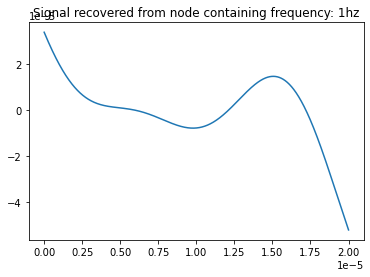

In [12]:
# Inverse transform from a single node
rec_0 = inv.inv_dwpt(transform_object, frequencies=1)
plt.plot(t_plot, rec_0)
plt.title("Signal recovered from node containing frequency: 1hz")
plt.show()

## 2.2 Testing inverse transform with synthetic data

The data is generated using the synthetic data package. Nodes are chosen for reconstruction and then the reconstructed sine wave is plotted alongside the transform results.

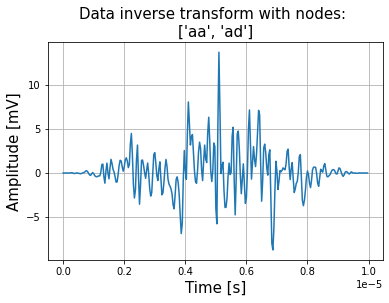

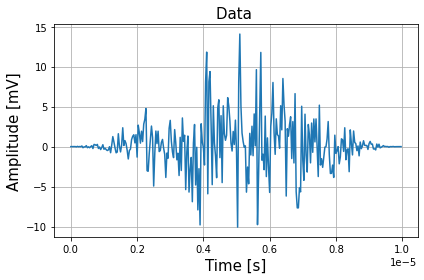

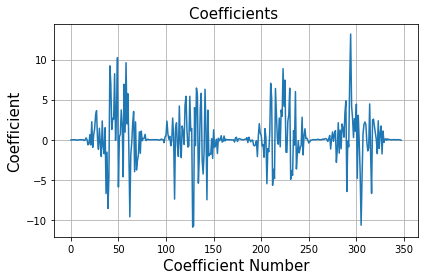

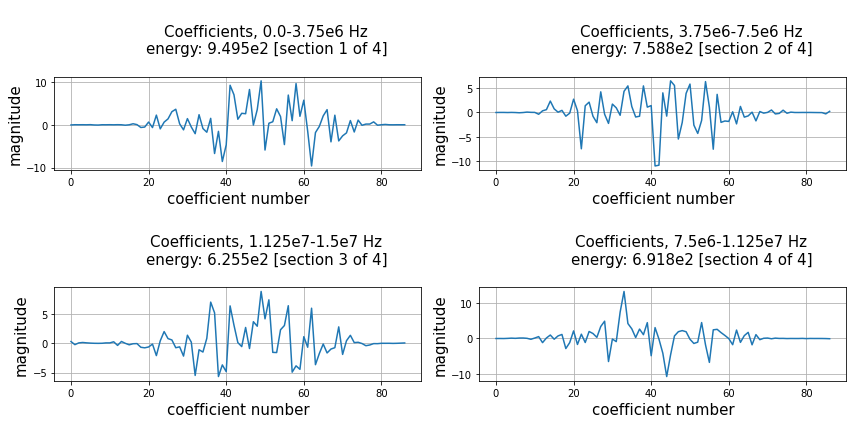

In [13]:
from numpy.random import seed

seed(seed = 1)

# set parameters for synthetic data
amp_sin_waves = 1 # amplitude of each sine wave that is added to the sound wave
sampling_rate = 30e6

test_frequencies = [1e6] # list of frequencies to test
harmonics = [1/4, 1/2, 1, 2, 3] # list of harmonics to test for each frequency

for frequency in test_frequencies:
    frequencies = frequency*np.array(harmonics)

    time_period = 1/frequency
    signal_duration = 10*time_period # signal duration is 10 times the period of the central frequency
    delay = 2*time_period # signal starts 2 time periods late
    end = 8*time_period # signal ends 2 time periods early

    gaussian_noise_std = 5 # set the standard devaition of the noise

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, phase, signal_duration, 
        sampling_rate, delay, end
        )

    gaussian_noise = sd.noise(gaussian_noise_std, signal_duration, sampling_rate)
    data += gaussian_noise
    data = signal.windows.hann(len(data)) * data

    # set parameters for transform
    levels = 2
    db_order = 9
    wavelet = f'db{db_order}'

    # transform
    transform_object = wpt.dwpt(data, levels, wavelet)
    final_nodes = transform_object.get_level(levels) # collect nodes from the last level
    transform_object.calc_frequencies(sampling_rate) # calculate the frequency ranges for each node

    nodes = ["aa", "ad"]  
    # takes same keyword arguments as packet_nodes_for_rec
    inverse = inv.inv_dwpt(transform_object, nodes=nodes)

    # plot inverse transform
    title = f'inverse transform with nodes: \n{nodes}'
    fig, ax = plt.subplots()
    plot.plot_wave(inverse, t_plot, ax, title)
    plt.show()

    # plot initial wave and transform coefficients
    full_plot(final_nodes, data, t_plot, sampling_rate)

### 3.0 Minimum entropy decomposition

Testing the minimum entropy decomposition 

see matlab documentation at https://uk.mathworks.com/help/wavelet/ug/wavelet-packets.html#

In [14]:
sampling_rate = 25E6

std_noise = 0.01

wavelet = "db1"
levels = 4
mode = "zero"

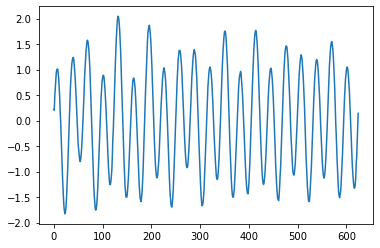

In [15]:
import wavelet_transform.utils.training_data as train

frequency = 8E5
pac = -1E5
R_init = 10E-6

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.get_data(R_init, frequency, pac, sampling_rate)
data = (data - np.mean(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))

plt.plot(data)
plt.show()

In [16]:
array = np.ones(16)
tr_obj = wpt.dwpt(array, wavelet="haar", mode="zero", min_entropy=True)
print("Entropy of leaf nodes:")
for node in tr_obj.get_leaf_nodes(order="freq"):
    print((node.level, node.node_number), f"{node.entropy:.4f}")

print("\nShannon Entropy of all nodes:")
for level in tr_obj.levels:
    for node in tr_obj.get_level(level):
        print((node.level, node.node_number), f"{node.entropy:.4f}")

Entropy of leaf nodes:
(4, 0) -0.0000
(4, 1) 0.0000
(3, 1) 0.0000
(2, 1) 0.0000
(1, 1) 0.0000

Shannon Entropy of all nodes:
(0, 0) 2.7726
(1, 0) 2.0794
(1, 1) 0.0000
(2, 0) 1.3863
(2, 1) 0.0000
(3, 0) 0.6931
(3, 1) 0.0000
(4, 0) -0.0000
(4, 1) 0.0000
